In [2]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
# warnings.filterwarnings('ignore')

In [4]:
df = pd.read_csv('insurance.csv');

In [5]:
df


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


In [6]:
df.describe()


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [8]:
df.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='object')

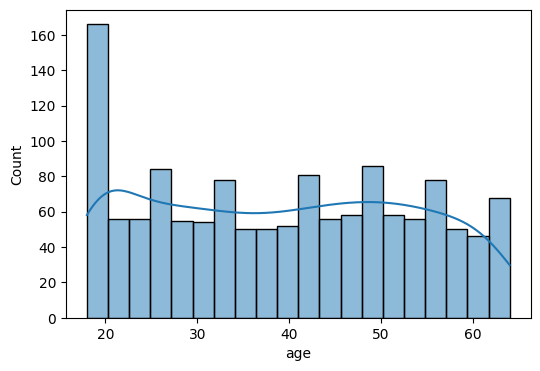

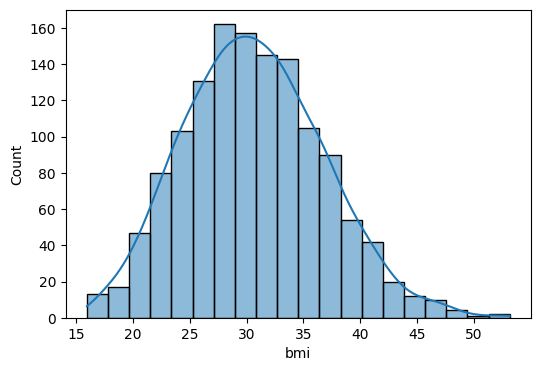

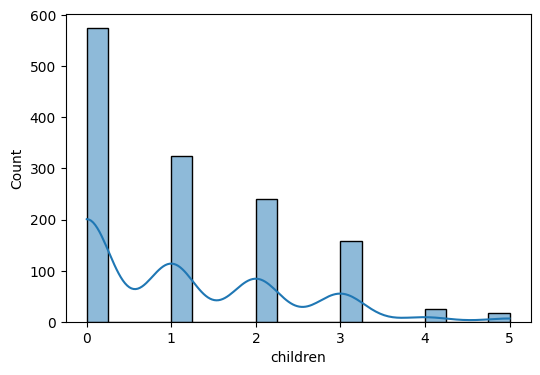

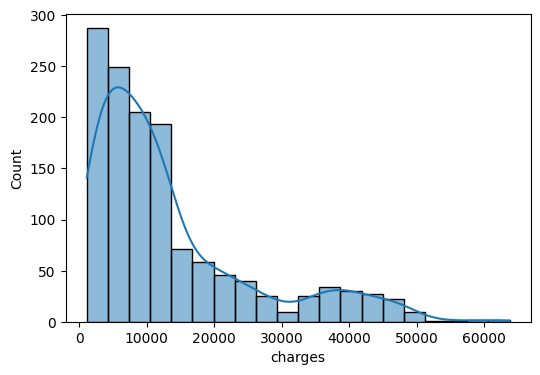

In [9]:
num_col = ['age', 'bmi', 'children',  'charges']
for col in num_col:
    plt.figure(figsize=(6,4))
    sns.histplot(df[col],kde=True ,bins=20)

<Axes: xlabel='children', ylabel='count'>

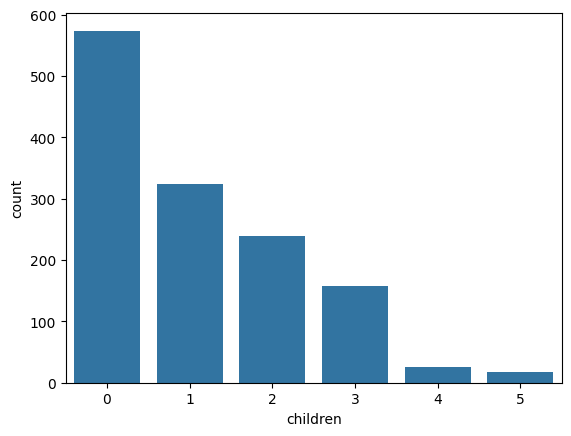

In [10]:
sns.countplot(x = df['children'])

<Axes: xlabel='sex', ylabel='count'>

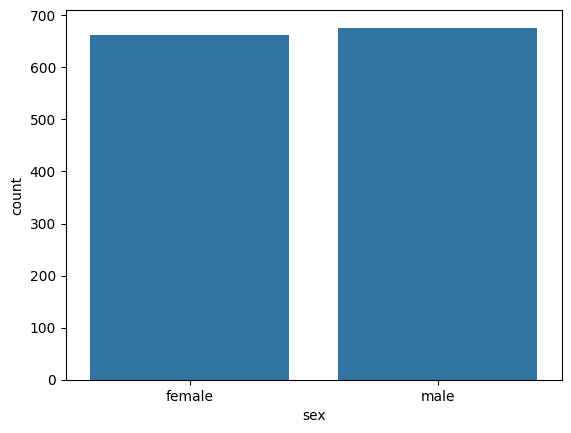

In [11]:
sns.countplot(x = df['sex'])

<Axes: xlabel='smoker', ylabel='count'>

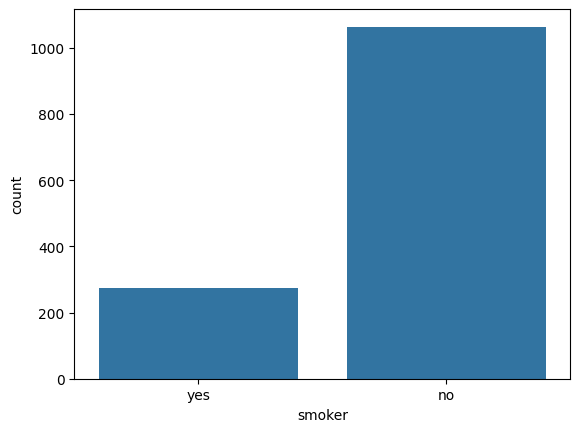

In [12]:
sns.countplot(x = df['smoker'])

In [1]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler

# 1. Load the raw data
print("Loading original insurance.csv...")
df = pd.read_csv('insurance.csv')

# 2. Convert text/categorical columns into numerical format
# drop_first=True reduces redundancy (e.g., 'sex_male' is enough, we don't need 'sex_female')
df_encoded = pd.get_dummies(df, columns=['sex', 'smoker', 'region'], drop_first=True)

# Convert all True/False or Integer values into Floats (Neural Networks prefer floats)
df_encoded = df_encoded.astype(float)

# 3. Separate the inputs (X) from the target output (y)
X = df_encoded.drop('charges', axis=1)
y = df_encoded['charges']

# 4. Normalize the input features to a scale between 0.0 and 1.0
print("Normalizing numerical inputs...")
scaler = MinMaxScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

# 5. Recombine the normalized inputs with the original target charges
df_final = pd.concat([X_scaled, y], axis=1)

# 6. Save the cleaned, model-ready data to a new file
output_filename = 'insurance_ready_for_training.csv'
df_final.to_csv(output_filename, index=False)

print(f"\nSuccess! Cleaned data saved as '{output_filename}'")
print(f"Final dataset shape: {df_final.shape[0]} rows, {df_final.shape[1]} columns.")
print("\nPreview of the first 3 rows:")
print(df_final.head(3))

Loading original insurance.csv...
Normalizing numerical inputs...

Success! Cleaned data saved as 'insurance_ready_for_training.csv'
Final dataset shape: 1338 rows, 9 columns.

Preview of the first 3 rows:
        age       bmi  children  sex_male  smoker_yes  region_northwest  \
0  0.021739  0.321227       0.0       0.0         1.0               0.0   
1  0.000000  0.479150       0.2       1.0         0.0               0.0   
2  0.217391  0.458434       0.6       1.0         0.0               0.0   

   region_southeast  region_southwest     charges  
0               0.0               1.0  16884.9240  
1               1.0               0.0   1725.5523  
2               1.0               0.0   4449.4620  
